# Just a Siblings' Thing: Choosing the Delphi Oracle

This notebook evaluates the supplied Ares, Athena, and Apollo binary classifiers on the held-out encounters. It follows the shared feature order from `model.py`, converts each model's logits to probabilities with the sigmoid function, and classifies at the required threshold of **0.50**. Since missing a catastrophic threat is especially costly, recall (sensitivity) is the key decision metric; accuracy is included for comparison.

## 1. Import Required Libraries

We use NumPy for numerical operations, pandas to read and summarize the CSV files, Matplotlib to visualize the sigmoid curve, and PyTorch to load and run the supplied checkpoints.

In [2]:
# NumPy supplies arrays and mathematical functions for probability/metric calculations.
import numpy as np

# Pandas reads the encounter and label CSV files and organizes metric results.
import pandas as pd

# Matplotlib draws the sigmoid curve so its probability mapping is visible.
import matplotlib.pyplot as plt

# PyTorch loads the provided neural-network checkpoints and runs inference.
import torch

# Import the exact shared model definition and feature order used during training.
from model import FEATURE_COLUMNS, MythicThreatClassifier

# Fix the classification rule requested in the task.
THRESHOLD = 0.50

# Use CPU inference so this notebook does not require a GPU.

## 2. Define the Sigmoid Function

The models return a real-valued **logit**, not a probability. The sigmoid maps a logit $z$ to a number between 0 and 1: $\sigma(z) = 1 / (1 + e^{-z})$. The code below also works with either a single number or a NumPy array.

In [3]:
# Define a helper that accepts one logit or an array of logits.
def sigmoid(logits):
    # Convert the input into a NumPy array for consistent scalar/array behavior.
    logits = np.asarray(logits, dtype=float)
    # Apply the logistic transformation, yielding values strictly between 0 and 1.
    return 1.0 / (1.0 + np.exp(-logits))

# Demonstrate the mapping for representative negative, zero, and positive logits.
sample_logits = np.array([-4.0, -1.0, 0.0, 1.0, 4.0])

# Print the corresponding probabilities rounded for readability.
print(pd.DataFrame({"logit": sample_logits, "sigmoid_probability": sigmoid(sample_logits).round(4)}))

   logit  sigmoid_probability
0   -4.0               0.0180
1   -1.0               0.2689
2    0.0               0.5000
3    1.0               0.7311
4    4.0               0.9820


## 3. Visualize the Sigmoid Function

The curve is monotonic: larger logits correspond to larger threat probabilities. A logit of zero maps to probability 0.50, which is the decision boundary used to turn model probabilities into binary predictions.

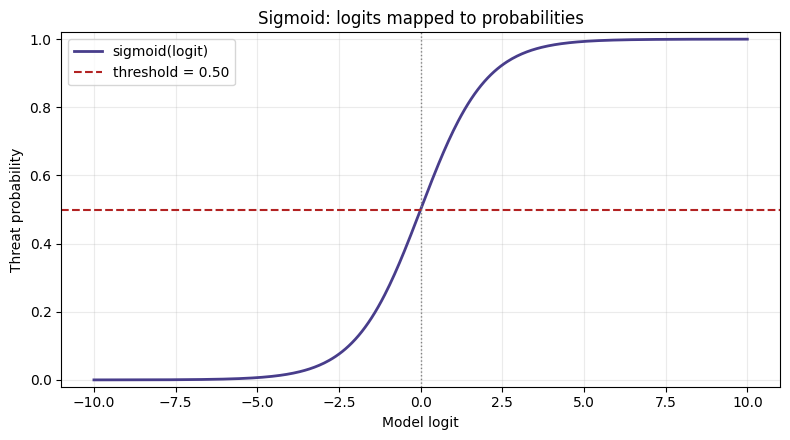

In [4]:
# Create evenly spaced logits from strongly negative to strongly positive.
logit_grid = np.linspace(-10.0, 10.0, 401)

# Convert every logit on the grid to its sigmoid probability.
probability_grid = sigmoid(logit_grid)

# Create a figure and axes for a readable curve plot.
fig, ax = plt.subplots(figsize=(8, 4.5))

# Draw the sigmoid curve as logit increases.
ax.plot(logit_grid, probability_grid, color="darkslateblue", linewidth=2, label="sigmoid(logit)")

# Mark probability 0.50, the required binary classification threshold.
ax.axhline(THRESHOLD, color="firebrick", linestyle="--", label="threshold = 0.50")

# Mark logit zero, which maps exactly to probability 0.50.
ax.axvline(0.0, color="gray", linestyle=":", linewidth=1)

# Add descriptive labels and a title to explain the axes.
ax.set(title="Sigmoid: logits mapped to probabilities", xlabel="Model logit", ylabel="Threat probability")

# Keep the vertical axis within the valid probability range.
ax.set_ylim(-0.02, 1.02)

# Show a light grid and a legend for readability.
ax.grid(alpha=0.25)
ax.legend()

# Adjust spacing and render the figure.
fig.tight_layout()
plt.show()

## 4. Apply Sigmoid to Sample Data

At the fixed threshold, a probability greater than or equal to 0.50 is predicted as a catastrophic threat (class 1); a smaller probability is predicted as class 0. These sample values illustrate the same rule used for the test-set model outputs.

In [5]:
# Set up a few artificial model logits to demonstrate prediction conversion.
sample_model_logits = np.array([-2.0, -0.2, 0.0, 0.7, 2.5])

# Convert those sample logits to estimated probabilities using the sigmoid.
sample_probabilities = sigmoid(sample_model_logits)

# Apply the task's 0.50 threshold to create 0/1 class predictions.
sample_predictions = (sample_probabilities >= THRESHOLD).astype(int)

# Display logits, probabilities, and the resulting predictions side by side.
sample_demo = pd.DataFrame({
    "logit": sample_model_logits,
    "probability": sample_probabilities.round(4),
    "predicted_class_at_0.50": sample_predictions,
})
print(sample_demo)

# Explain the class-1 decision rule in the output.
print("A sample is flagged as a threat when its probability is >=", THRESHOLD)

   logit  probability  predicted_class_at_0.50
0   -2.0       0.1192                        0
1   -0.2       0.4502                        0
2    0.0       0.5000                        1
3    0.7       0.6682                        1
4    2.5       0.9241                        1
A sample is flagged as a threat when its probability is >= 0.5


## 5. Load the Provided Test Data and Model Architecture

This is the actual evaluation path. We read the supplied test files, verify that feature rows and labels refer to the same encounters in the same order, and select only the nine numeric inputs in the shared architecture's declared `FEATURE_COLUMNS` order. The region and moon-phase columns are not model inputs.

In [6]:
# Load encounter features and ground-truth labels from the CSV files beside this notebook.
test_features = pd.read_csv("test_dataset.csv")
test_labels = pd.read_csv("test_labels.csv")

# Verify there is a one-to-one row match before combining features and labels.
assert test_features["encounter_id"].equals(test_labels["encounter_id"]), "Encounter IDs or row order do not match."

# Select inputs in precisely the order expected by the shared PyTorch model.
feature_array = test_features[FEATURE_COLUMNS].to_numpy(dtype=np.float32)

# Confirm all model inputs are present and finite before inference.
assert np.isfinite(feature_array).all(), "Model features contain missing or non-finite values."

# Convert numeric feature values to a PyTorch tensor for model evaluation.
X_test = torch.from_numpy(feature_array)

# Convert the target labels to an integer NumPy array for metric calculations.
y_true = test_labels["is_catastrophic_threat"].to_numpy(dtype=int)

# Print the test-set size and threat prevalence to establish the evaluation context.
print(f"Test encounters: {len(y_true)}")
print(f"Catastrophic threats: {int(y_true.sum())} ({y_true.mean():.1%})")
print("Model input order:", FEATURE_COLUMNS)

Test encounters: 1000
Catastrophic threats: 100 (10.0%)
Model input order: ['creature_mass_talents', 'oracle_omen', 'aggression_index', 'divine_aura', 'aegis_resonance', 'armor_resistance', 'witness_count', 'styx_disturbance', 'omen_intensity']


## 6. Evaluate All Three Models at Threshold 0.50

For each checkpoint, we load the same architecture and test inputs, pass logits through sigmoid, and use probability $\geq 0.50$ as the positive prediction. We report confusion counts plus accuracy, precision, recall/sensitivity, specificity, F1, ROC-AUC, and average precision. Recall directly measures the fraction of true catastrophic threats detected; false negatives are the missed threats.

In [7]:
# Prepare a list to collect the evaluation results for each oracle model.
metric_rows = []

# Iterate over each supplied checkpoint by its oracle name.
for model_name in ["ares", "athena", "apollo"]:
    # Create an instance of the shared network architecture.
    classifier = MythicThreatClassifier()

    # Load this model's trained weights onto the CPU; weights_only avoids loading arbitrary objects.
    checkpoint = torch.load(f"models/model_{model_name}.pth", map_location="cpu", weights_only=True)

    # Copy the checkpoint parameters into the matching model architecture.
    classifier.load_state_dict(checkpoint)

    # Put the model in evaluation mode so inference is deterministic and uses evaluation behavior.
    classifier.eval()

    # Disable gradient tracking because this notebook only evaluates, not trains, the model.
    with torch.no_grad():
        # Run the test features through the model to get raw logits.
        logits = classifier(X_test)

        # Convert the logits to threat probabilities with the sigmoid function.
        probabilities = torch.sigmoid(logits).cpu().numpy()

    # Classify probabilities at or above 0.50 as catastrophic threats (class 1).
    y_pred = (probabilities >= THRESHOLD).astype(int)

    # Count true positives: threats correctly predicted as threats.
    tp = int(((y_true == 1) & (y_pred == 1)).sum())

    # Count false positives: non-threats incorrectly predicted as threats.
    fp = int(((y_true == 0) & (y_pred == 1)).sum())

    # Count true negatives: non-threats correctly predicted as non-threats.
    tn = int(((y_true == 0) & (y_pred == 0)).sum())

    # Count false negatives: real threats incorrectly predicted as non-threats.
    fn = int(((y_true == 1) & (y_pred == 0)).sum())

    # Compute precision: among predicted threats, the fraction that are true threats.
    precision = tp / (tp + fp) if (tp + fp) else 0.0

    # Compute recall/sensitivity: among true threats, the fraction detected by the model.
    recall = tp / (tp + fn) if (tp + fn) else 0.0

    # Compute specificity: among true non-threats, the fraction correctly rejected.
    specificity = tn / (tn + fp) if (tn + fp) else 0.0

    # Compute F1 as the harmonic mean of precision and recall.
    f1 = (2 * precision * recall / (precision + recall)) if (precision + recall) else 0.0

    # Split probabilities into actual positive and negative classes for ROC-AUC.
    positive_scores = probabilities[y_true == 1]
    negative_scores = probabilities[y_true == 0]

    # Calculate ROC-AUC from all positive-negative score pairs; ties contribute one-half.
    pairwise_auc = (
        (positive_scores[:, None] > negative_scores).sum()
        + 0.5 * (positive_scores[:, None] == negative_scores).sum()
    ) / (len(positive_scores) * len(negative_scores))

    # Sort scores from highest to lowest to compute average precision at score thresholds.
    score_order = np.argsort(-probabilities, kind="stable")
    sorted_scores = probabilities[score_order]
    sorted_labels = y_true[score_order]

    # Find the final row of each tied-score group so each distinct threshold is counted once.
    threshold_ends = np.r_[np.flatnonzero(np.diff(sorted_scores)), len(sorted_scores) - 1]

    # Count true positives at the end of each distinct score threshold.
    cumulative_tp = np.cumsum(sorted_labels)[threshold_ends]

    # Compute precision at each distinct score threshold.
    threshold_precision = cumulative_tp / (threshold_ends + 1)

    # Compute recall at each distinct score threshold.
    threshold_recall = cumulative_tp / int(y_true.sum())

    # Sum precision weighted by recall increases to obtain average precision.
    average_precision = np.sum(np.diff(np.r_[0.0, threshold_recall]) * threshold_precision)

    # Save the model name, decision counts, and calculated metrics in one results row.
    metric_rows.append({
        "Model": model_name.upper(),
        "Accuracy": (tp + tn) / len(y_true),
        "Precision": precision,
        "Recall / sensitivity": recall,
        "Specificity": specificity,
        "F1": f1,
        "ROC-AUC": float(pairwise_auc),
        "Average precision": float(average_precision),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
    })

# Put all per-model results into a labeled table for direct comparison.
metric_table = pd.DataFrame(metric_rows).set_index("Model")

# Display metrics rounded to four decimal places while retaining counts as integers.
display(metric_table.round(4))

,Accuracy,Precision,Recall / sensitivity,Specificity,F1,ROC-AUC,Average precision,TN,FP,FN,TP
Model,,,,,,,,,,,
ARES,0.95,0.6786,0.95,0.9500,0.7917,0.9471,0.6970,855,45,5,95
ATHENA,0.95,0.7500,0.75,0.9722,0.7500,0.8766,0.6389,875,25,25,75
APOLLO,0.95,0.9167,0.55,0.9944,0.6875,0.7859,0.6105,895,5,45,55


## 7. Explain the SIGMOID_ARES Solution

Accuracy is 0.95 for all three models, so it does not separate them. The test set has 100 actual threats. Ares detects 95 (recall 0.95) and misses 5; Athena detects 75 and misses 25; Apollo detects 55 and misses 45. Ares has more false alarms than the others, but the stated deployment cost makes missed threats the priority. We therefore select the model with the highest recall at the specified 0.50 threshold.

In [8]:
# Check that the three observed accuracy values are all equal within rounding tolerance.
accuracies_match = np.allclose(metric_table["Accuracy"].to_numpy(), metric_table["Accuracy"].iloc[0])

# Choose the oracle with the highest recall because false negatives are especially costly.
selected_model = metric_table["Recall / sensitivity"].idxmax()

# Format the required challenge flag using the selected model's uppercase name.
flag = f"SIGMOID_{selected_model}"

# Print the accuracy comparison and recall-based decision as the final evidence.
print(f"All three models have the same accuracy: {accuracies_match}")
print("Recall by model:")
print(metric_table["Recall / sensitivity"].sort_values(ascending=False))
print(f"Selected model: {selected_model}")
print(f"Flag: {flag}")

# Fail loudly if the measured data no longer supports the expected answer.
assert accuracies_match, "The models no longer have equal accuracy on this test set."
assert flag == "SIGMOID_ARES", "Recheck the loaded data, checkpoints, and metric calculations."

All three models have the same accuracy: True
Recall by model:
Model
ARES      0.95
ATHENA    0.75
APOLLO    0.55
Name: Recall / sensitivity, dtype: float64
Selected model: ARES
Flag: SIGMOID_ARES
